In a reactor with excess A, the reaction A+B=C reaches equilibrium initial are A=2 B=1 C=0 mol/L if x mol/L of c is formed kcx**2-(3kc=1)x+2kc=0

In [7]:
# Equilibrium example with excess A: initial concentrations A=2, B=1, C=0.

try:
    kc = float(input("Enter the value of Kc: "))
    A=2
    B=1
    C=0
    a = kc
    b = -(3 * kc + 1)
    c = 2 * kc

    # Kc = x / ((2 - x) * (1 - x))
    # Rearranged: Kc*x**2 - (3*Kc + 1)*x + 2*Kc = 0.
    discriminant = b**2 - 4 * a * c
    print("Discriminant:", discriminant)

    if kc <= 0:
        print("Invalid input: Kc must be greater than 0.")
    elif discriminant < 0:
        print("No real equilibrium roots.")
    else:
        root1 = (-b + discriminant**0.5) / (2 * a)
        root2 = (-b - discriminant**0.5) / (2 * a)
        print("x1:", root1, "and x2:", root2)

        #root must be between 0 and 1
        valid_roots = [root for root in (root1, root2) if 0 <= root <= 1]

         # At equilibrium: [A] = 2 - x, [B] = 1 - x, [C] = x.
        if valid_roots:     
            x = valid_roots[0]
            concentration_a = 2 - x
            concentration_b = 1 - x
            concentration_c = x
            conversion_of_limiting_reactant_B = x / B * 100

            print("Physically meaningful root x:", x)
            print("Equilibrium concentrations:")
            print(f"A: {concentration_a:.3f}")
            print(f"B: {concentration_b:.3f}")
            print(f"C: {concentration_c:.3f}")
            print(f"Conversion of limiting reactant B: {conversion_of_limiting_reactant_B:.2f}%")
            
            #condition apply for grading system
            if conversion_of_limiting_reactant_B >=70:  
                print(f"Conversion of limiting reactant B is High")
            elif 40<= conversion_of_limiting_reactant_B < 70:
                print("Conversion of limiting reactant B is Moderate")
            else:
                print("Conversion of limiting reactant B is Low")
        else:
            print("No root satisfies the physical range 0 <= x <= 1.")
except ValueError:
    print("Invalid input: Please enter a numeric value for Kc.")       

Discriminant: 4.25
x1: 4.561552812808831 and x2: 0.4384471871911697
Physically meaningful root x: 0.4384471871911697
Equilibrium concentrations:
A: 1.562
B: 0.562
C: 0.438
Conversion of limiting reactant B: 43.84%
Conversion of limiting reactant B is Moderate


Hydrogen peroxide decompose in a batch reactor by a first order reaction dc/dt=-kc use the euler method c-new+c-old-kc_old delta t  take co=1.5 k=0.05min delta t=2min

In [1]:
import math

C0 = 1.5
k = 0.05       # 1/min
delta_t = 2    # min

# Euler simulation for 20 minutes
time = 0
concentration = C0

print("Euler simulation")
print(f"{'Time (min)':>10} {'Concentration':>16} {'Conversion (%)':>16}")
print(f"{time:10.1f} {concentration:16.4f} {0.0:16.2f}")

for step in range(1, 21 // delta_t + 1):
    concentration_old = concentration
    concentration = concentration_old - k * concentration_old * delta_t
    time = step * delta_t

    conversion = (C0 - concentration) / C0 * 100
    print(f"{time:10.1f} {concentration:16.4f} {conversion:16.2f}")

# Exact concentration at 20 minutes: C(t) = C0 * exp(-k*t)
exact_concentration = C0 * math.exp(-k * 20)
absolute_error = abs(concentration - exact_concentration)

print(f"\nEuler concentration at 20 min: {concentration:.6f}")
print(f"Exact concentration at 20 min: {exact_concentration:.6f}")
print(f"Absolute error: {absolute_error:.6f}")


# Repeat with a while loop until conversion reaches 50% or time reaches 100 min
time = 0
concentration = C0
target_conversion = 50
maximum_time = 100

while time < maximum_time:
    conversion = (C0 - concentration) / C0 * 100

    if conversion >= target_conversion:
        break

    concentration_old = concentration
    concentration = concentration_old - k * concentration_old * delta_t
    time += delta_t

final_conversion = (C0 - concentration) / C0 * 100

print("\nWhile-loop simulation")
print(f"Time: {time} min")
print(f"Final concentration: {concentration:.6f}")
print(f"Conversion: {final_conversion:.2f}%")

if final_conversion >= target_conversion:
    print("The 50% conversion target was reached.")
else:
    print("The 50% conversion target was not reached within 100 minutes.")

Euler simulation
Time (min)    Concentration   Conversion (%)
       0.0           1.5000             0.00
       2.0           1.3500            10.00
       4.0           1.2150            19.00
       6.0           1.0935            27.10
       8.0           0.9842            34.39
      10.0           0.8857            40.95
      12.0           0.7972            46.86
      14.0           0.7174            52.17
      16.0           0.6457            56.95
      18.0           0.5811            61.26
      20.0           0.5230            65.13

Euler concentration at 20 min: 0.523018
Exact concentration at 20 min: 0.551819
Absolute error: 0.028802

While-loop simulation
Time: 14 min
Final concentration: 0.717445
Conversion: 52.17%
The 50% conversion target was reached.


actor tag such as reactor-07/b-2026 are stored as text write a proigram that reads a tag loop through eaqch character and print the number of digit and sum of digits show a message for an empty tag and for tag with no digit test with reactor-07/b-206 anbd emtpy tag and abcdef

In [43]:
def analyze_tag(tag):
    if tag == "":
        print("Tag is empty.")
        return

    digit_count = 0
    digit_sum = 0

    for character in tag:
        if character.isdigit():
            digit = int(character)
            digit_count += 1
            digit_sum += digit

    if digit_count == 0:
        print(f"Tag {tag!r} contains no digits.")
    else:
        print(f"Tag: {tag}")
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


# Test cases
for tag in ["reactor-07/b-206", "", "abcdef"]:
    analyze_tag(tag)
    print()

Tag: reactor-07/b-206
Number of digits: 5
Sum of digits: 15

Tag is empty.

Tag 'abcdef' contains no digits.



a labroratory has n candidate catalyts and want to test r of them together write a recursive function factoial n and function combination that uses it reject invalid input r>n print number of possible catalyst sets for n =7 r=2 and show message n=4 and r=6

In [45]:
def factorial(n):
    if n == 0 or n == 1:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if r > n:
        print(f"Invalid input: r ({r}) cannot be greater than n ({n}).")
        return None

    return factorial(n) // (factorial(r) * factorial(n - r))


# Test cases
result = combination(7, 2)
if result is not None:
    print(f"For n=7 and r=2, there are {result} possible catalyst sets.")

combination(4, 6)

For n=7 and r=2, there are 21 possible catalyst sets.
Invalid input: r (6) cannot be greater than n (4).


during a distillation run saqmple are taken at time=fibonacci number * 5 min write and iterative function fib_iter(n) that return a list of the first n fibbonnaci nuber and recurssive function fib_rec(k) that return the k-th fibonnaci number f=0 f1=1 for n=9 check both function agree and print a table sample no fibonnaci tag sampling time min

In [46]:
def fib_iter(n):
    """Return the first n Fibonacci numbers, starting with 0, 1."""
    if n < 0:
        raise ValueError("n must be non-negative")

    numbers = []
    a, b = 0, 1

    for _ in range(n):
        numbers.append(a)
        a, b = b, a + b

    return numbers


def fib_rec(k):
    """Return the k-th Fibonacci number, with F0=0 and F1=1."""
    if k < 0:
        raise ValueError("k must be non-negative")
    if k <= 1:
        return k
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 9
fib_numbers = fib_iter(n)

# Check the iterative and recursive functions agree
assert all(fib_numbers[k] == fib_rec(k) for k in range(n))
print("The iterative and recursive results agree.")

print(f"{'Sample no.':<12}{'Fibonacci tag':<16}{'Sampling time (min)':<20}")
for sample_no, fib_number in enumerate(fib_numbers, start=1):
    sampling_time = fib_number * 5
    print(f"{sample_no:<12}{fib_number:<16}{sampling_time:<20}")

The iterative and recursive results agree.
Sample no.  Fibonacci tag   Sampling time (min) 
1           0               0                   
2           1               5                   
3           1               5                   
4           2               10                  
5           3               15                  
6           5               25                  
7           8               40                  
8           13              65                  
9           21              105                 


Create 2 dataframe consist of conc and time

In [ ]:
import pandas as pd

kinetics_and_gas_df_1 = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Concentration_mol_L": [1.20, 0.98, 0.80, 0.66, 0.54, 0.44]
})

kinetics_and_gas_df_2 = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Concentration_mol_L": [1.20, 0.98, 0.54, 0.36, 0.24, 0.16]
})

display(kinetics_and_gas_df_1)
display(kinetics_and_gas_df_2)


,Time_min,Concentration_mol_L
0,0,1.20
1,10,0.98
2,20,0.80
3,30,0.66
4,40,0.54
5,50,0.44


,Time_min,Concentration_mol_L
0,0,1.20
1,10,0.98
2,20,0.54
3,30,0.36
4,40,0.24
5,50,0.16


In [18]:
combined_df = pd.merge(
    kinetics_and_gas_df_1,
    kinetics_and_gas_df_2,
    on="Time_min",
    suffixes=("_1", "_2")
)

combined_df

combined_df.to_csv("kinetics.csv", index=False)
combined_df.to_json("kinetics.json", orient="records")

In [21]:
pd.read_csv("kinetics.csv")
print(pd.read_csv("kinetics.csv").shape)
print(pd.read_csv("kinetics.csv").dtypes)

(6, 3)
Time_min                   int64
Concentration_mol_L_1    float64
Concentration_mol_L_2    float64
dtype: object


Mean and standard Deriation

In [44]:
summary = pd.DataFrame({
    "Mean": [
        kinetics_and_gas_df_1["Concentration_mol_L"].mean(),
        kinetics_and_gas_df_2["Concentration_mol_L"].mean()
    ],
    "Standard deviation": [
        kinetics_and_gas_df_1["Concentration_mol_L"].std(),
        kinetics_and_gas_df_2["Concentration_mol_L"].std()
    ]
}, index=["run 1", "run 2"])

print(summary)

more_variable = summary["Standard deviation"].idxmax()
print(f"{more_variable} has more variation.")

       Mean  Standard deviation
run 1  0.77            0.284183
run 2  0.58            0.421046
run 2 has more variation.


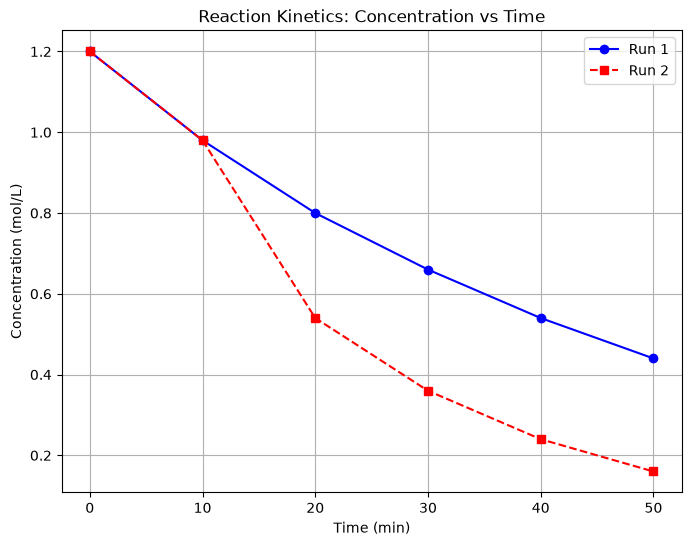

In [28]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.plot(kinetics_and_gas_df_1['Time_min'], kinetics_and_gas_df_1['Concentration_mol_L'], marker='o', linestyle='-', color='b')
plt.plot(kinetics_and_gas_df_2['Time_min'], kinetics_and_gas_df_2['Concentration_mol_L'], marker='s', linestyle='--', color='r')
plt.title('Reaction Kinetics: Concentration vs Time')
plt.xlabel('Time (min)')
plt.ylabel('Concentration (mol/L)')
plt.legend(['Run 1', 'Run 2'])
plt.grid()
plt.savefig('reaction_kinetics_two_runplot.png')

In [31]:
pressure_and_volume_df = pd.DataFrame({
    "Volume_L": [1.0, 2.0, 3.0, 4.0, 5.0],
    "Pressure_kPa": [3.02, 1.49, 1.01, 0.76, 0.59]
})  

pressure_and_volume_df

,Volume_L,Pressure_kPa
0,1.0,3.02
1,2.0,1.49
2,3.0,1.01
3,4.0,0.76
4,5.0,0.59


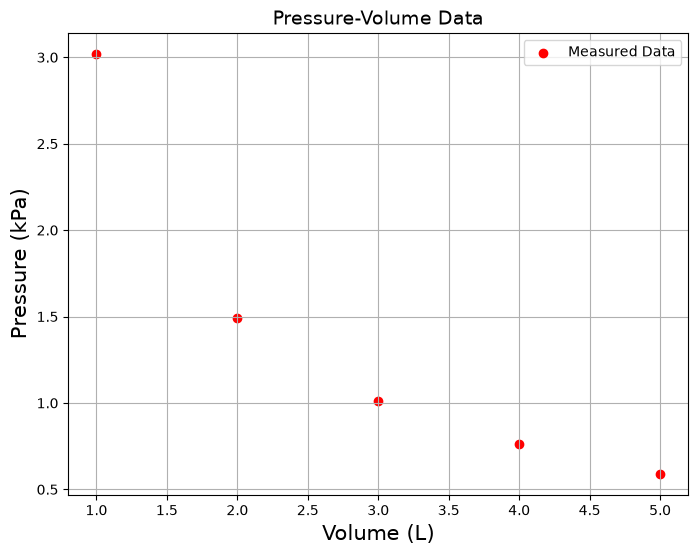

In [39]:
# Final pressure-versus-volume plot.
plt.figure(figsize=(8, 6))
plt.scatter(pressure_and_volume_df['Volume_L'], pressure_and_volume_df['Pressure_kPa'], color='r', label='Measured Data',marker='o', linestyle='-')

plt.title('Pressure-Volume Data', fontsize=14)
plt.xlabel('Volume (L)', fontsize=15)
plt.ylabel('Pressure (kPa)', fontsize=15)
plt.legend(fontsize=13)
plt.grid()
plt.legend()


plot pressure vs volume as a scatter plot.calculate K as mean of p * v and draw the reference cuve p=k/v on same graph add title with units and legend

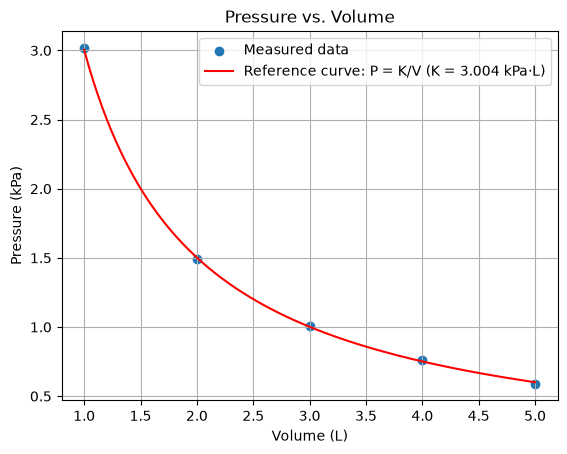

Mean K = 3.004 kPa·L


In [41]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate K as the mean of P * V
K = (pressure_and_volume_df["Pressure_kPa"] *
     pressure_and_volume_df["Volume_L"]).mean()

# Smooth reference curve: P = K / V
volume_curve = np.linspace(
    pressure_and_volume_df["Volume_L"].min(),
    pressure_and_volume_df["Volume_L"].max(),
    200
)
pressure_curve = K / volume_curve

plt.scatter(
    pressure_and_volume_df["Volume_L"],
    pressure_and_volume_df["Pressure_kPa"],
    label="Measured data"
)
plt.plot(volume_curve, pressure_curve, color="red",
         label=f"Reference curve: P = K/V (K = {K:.3f} kPa·L)")

plt.title("Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (kPa)")
plt.legend()
plt.grid(True)
plt.show()

print(f"Mean K = {K:.3f} kPa·L")